In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%config InlineBackend.figure_format = 'retina'

df = pd.read_csv('./nepal_building_damage.csv')

df.shape

(260601, 40)

## EDA

### 1. 종속변수(`damage_grade`) 분포도

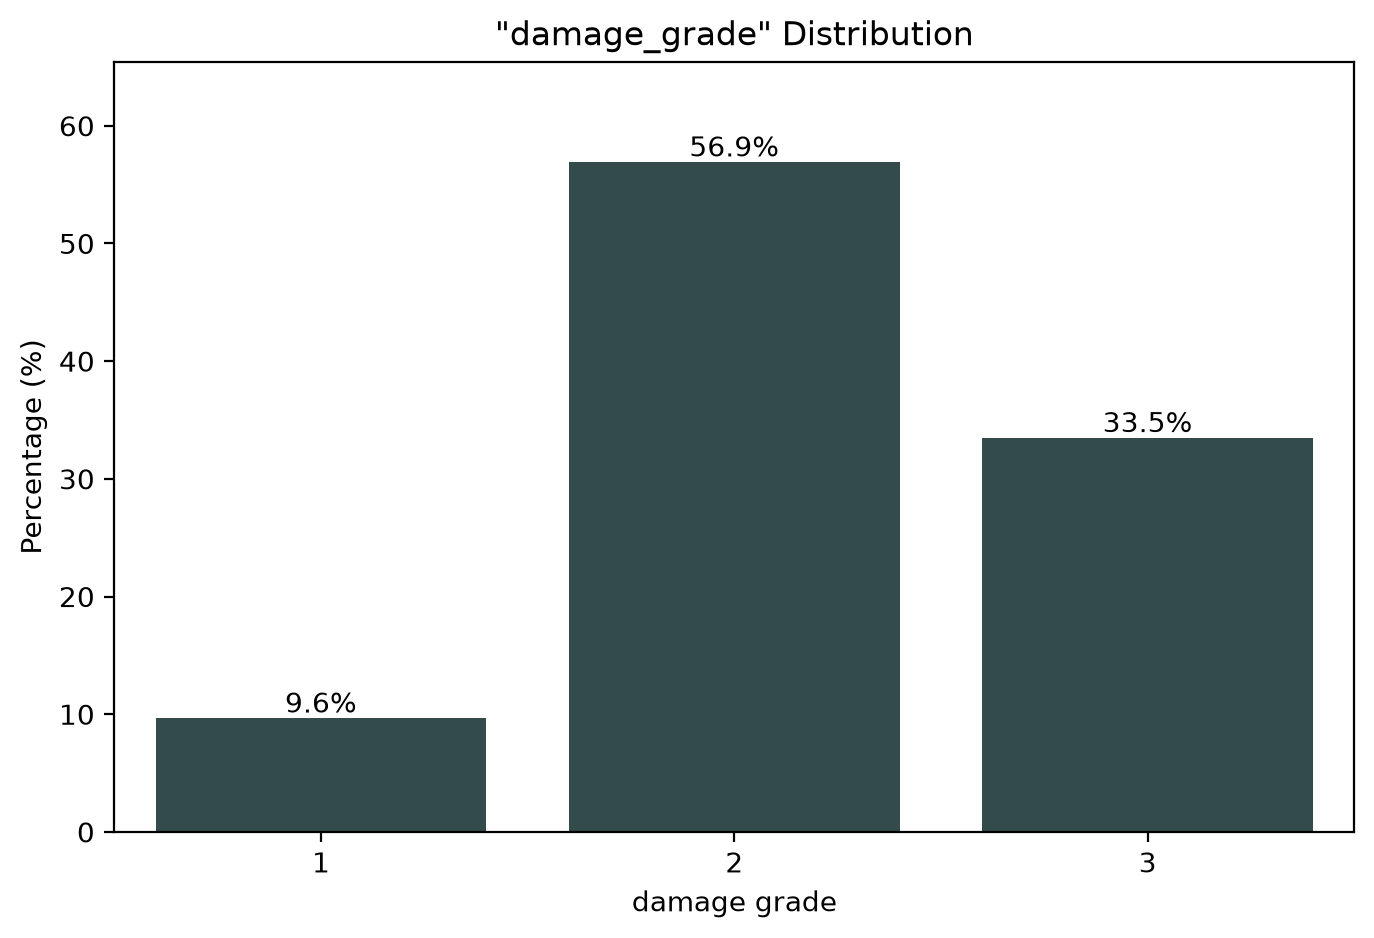

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 피해 등급별 비율 계산
ratio = df['damage_grade'].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(x=ratio.index, y=ratio.values, color='darkslategray')

# 막대 위에 비율 표시
for i, v in enumerate(ratio.values):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center')

plt.title('"damage_grade" Distribution')
plt.xlabel('damage grade')
plt.ylabel('Percentage (%)')
plt.ylim(0, ratio.max() * 1.15)

plt.show()

### 2. 건물 연령(`age`) 분포 파악 

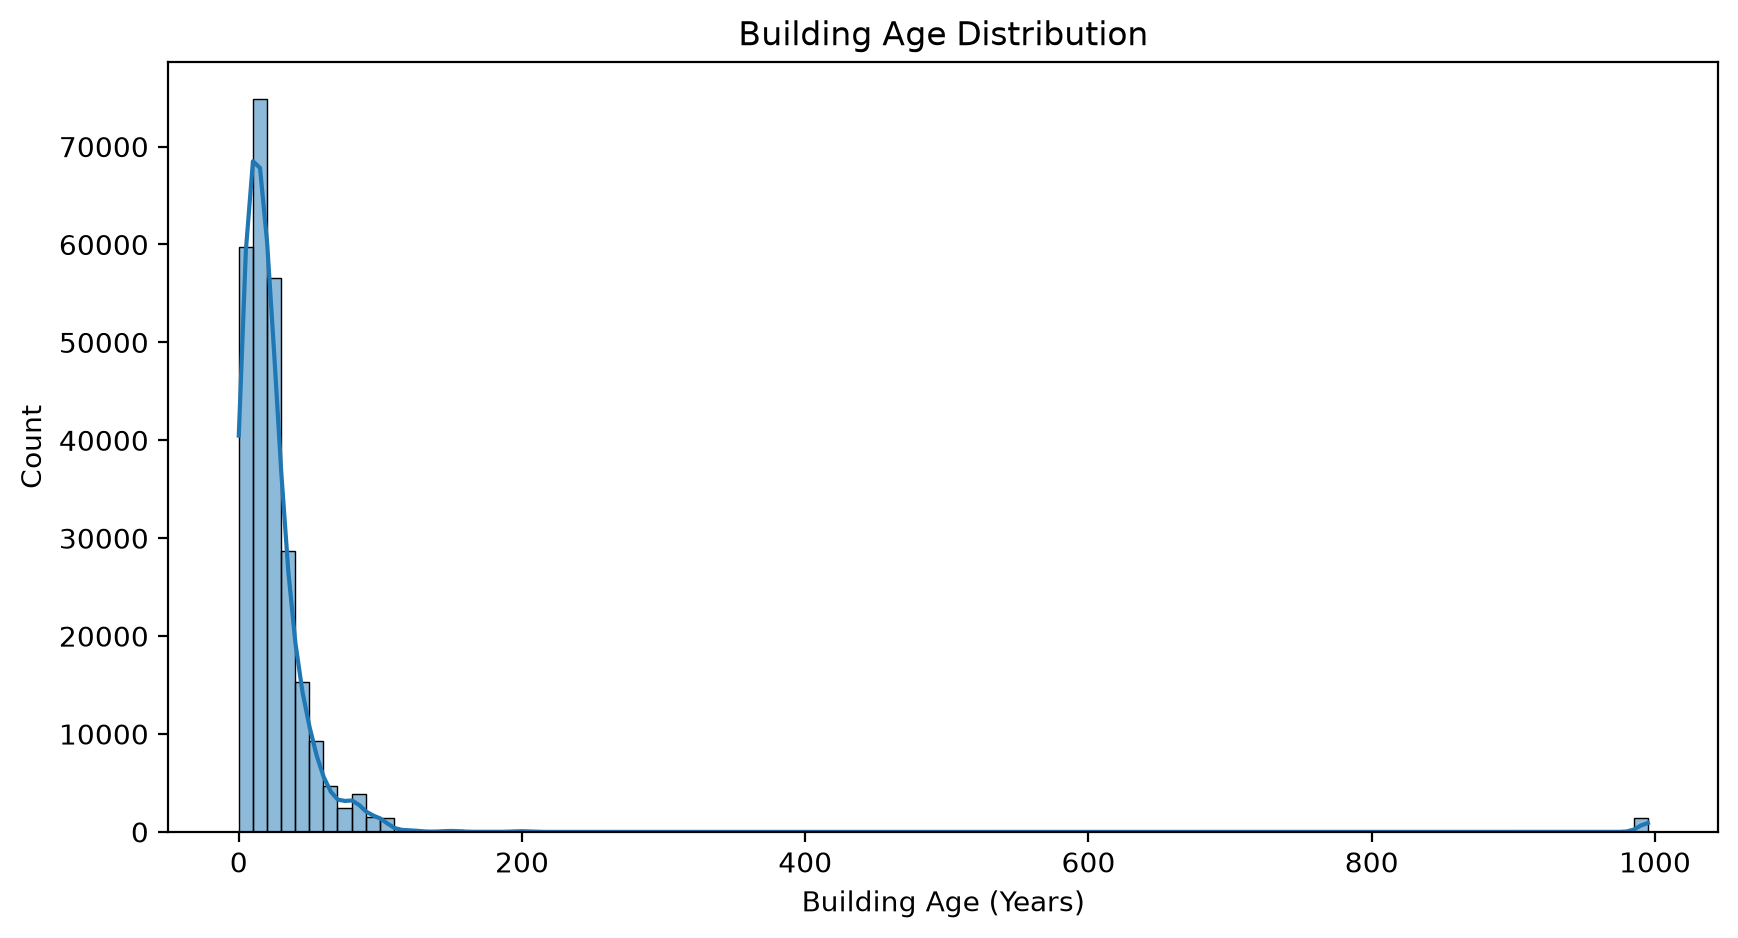

In [3]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='age', bins=100, kde=True)

plt.title('Building Age Distribution')
plt.xlabel('Building Age (Years)')
plt.ylabel('Count')

plt.show()

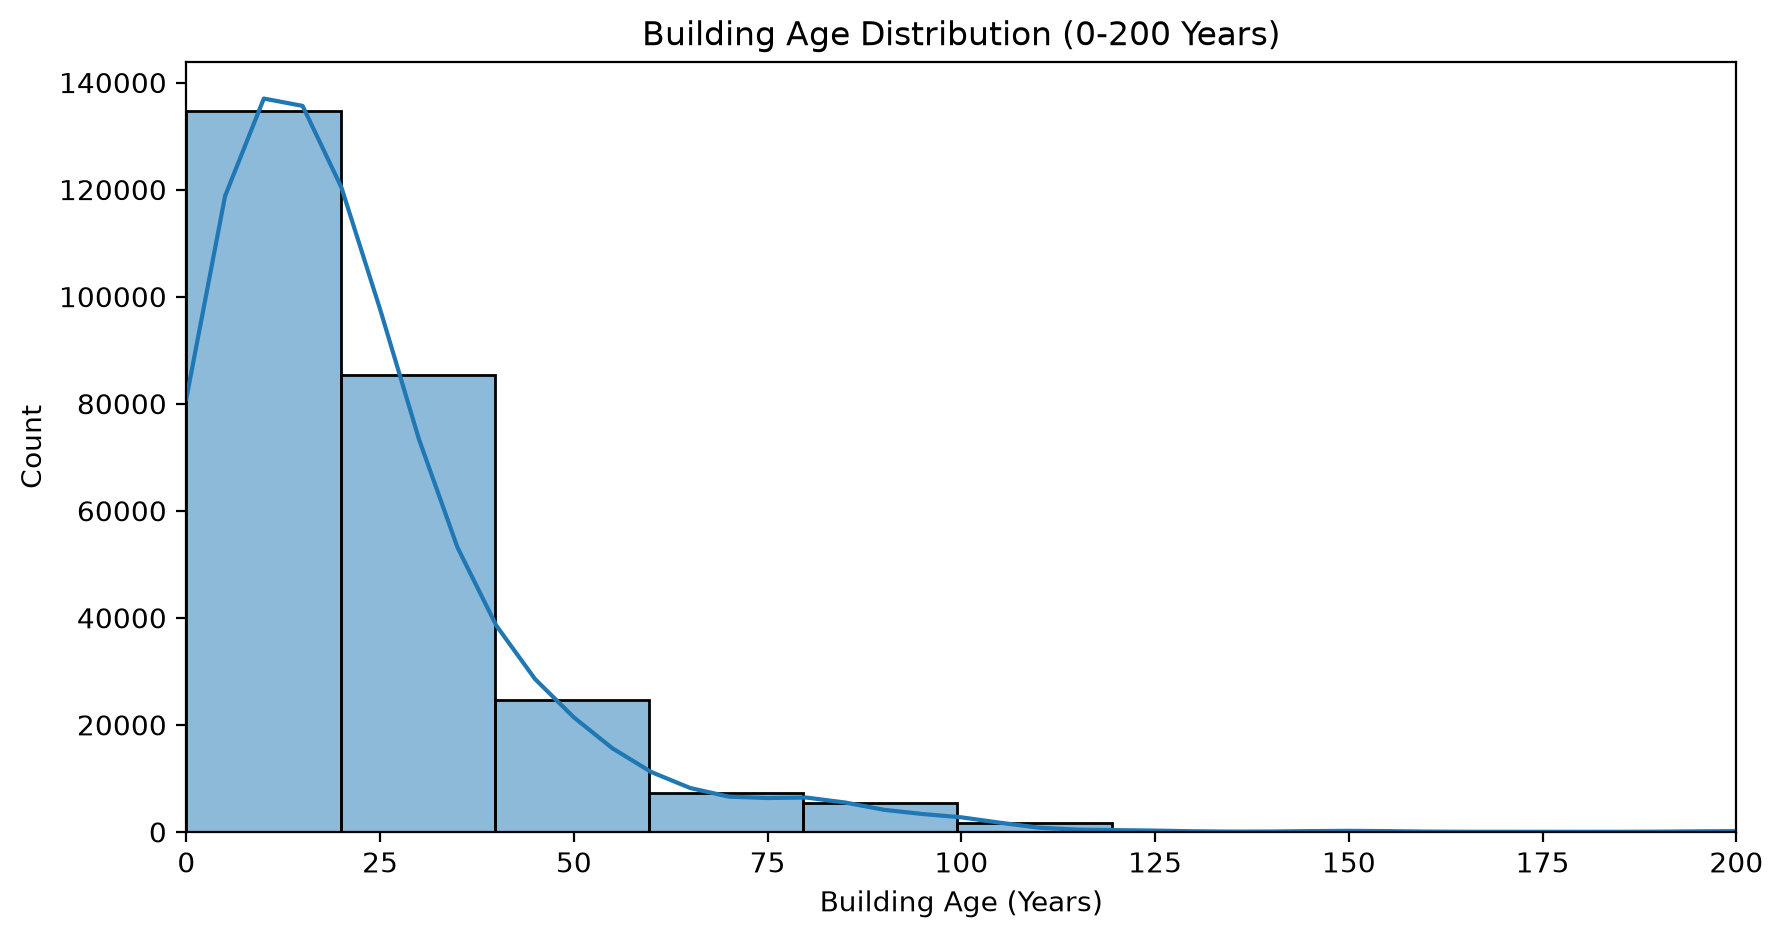

In [4]:
# 0 ~ 200년의 건물 나이 분포도

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='age', bins=50, kde=True)

plt.xlim(0, 200)

plt.title('Building Age Distribution (0-200 Years)')
plt.xlabel('Building Age (Years)')
plt.ylabel('Count')

plt.show()

### 3. 이상치 파악(연속형 변수)

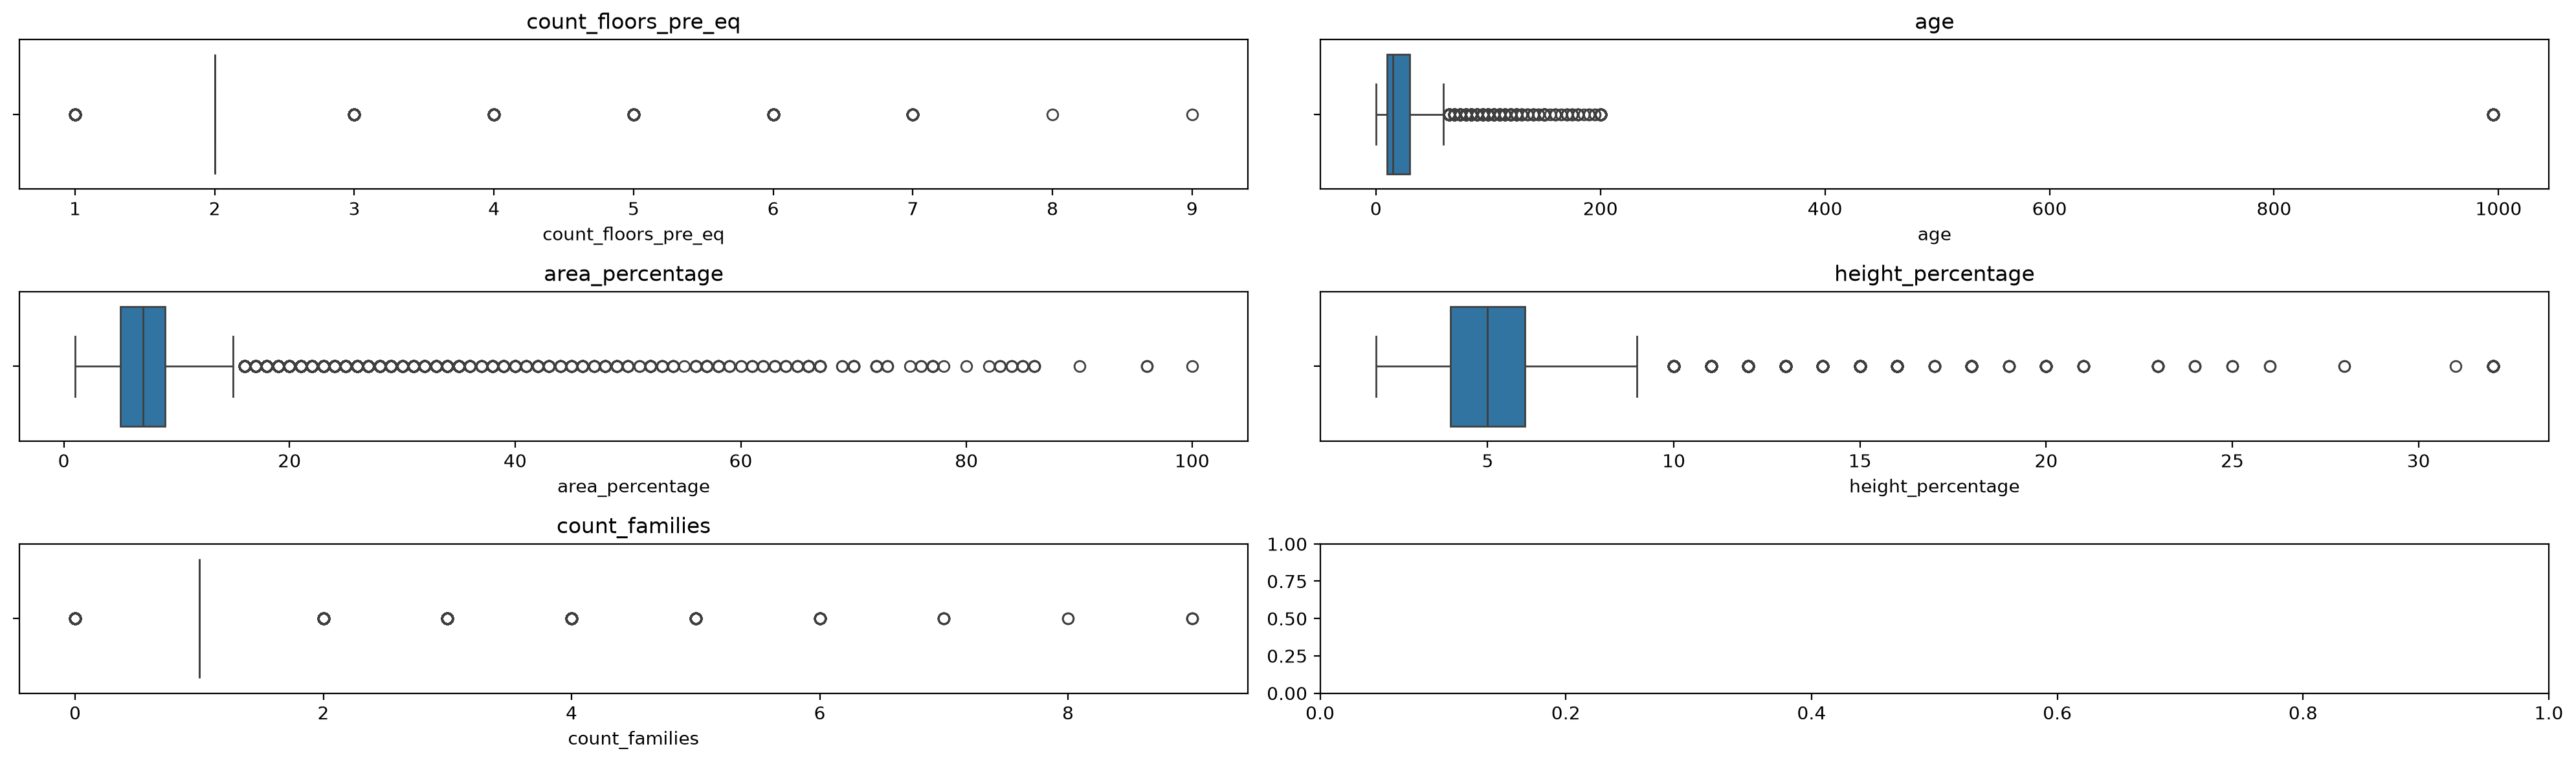

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

fig, ax = plt.subplots(3, 2, figsize=(20, 6))

ax = ax.flatten()

for num, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=ax[num])
    ax[num].set_title(col)

plt.tight_layout()

plt.show()

### 4. 건물 연식 VS 건물 피해 강도

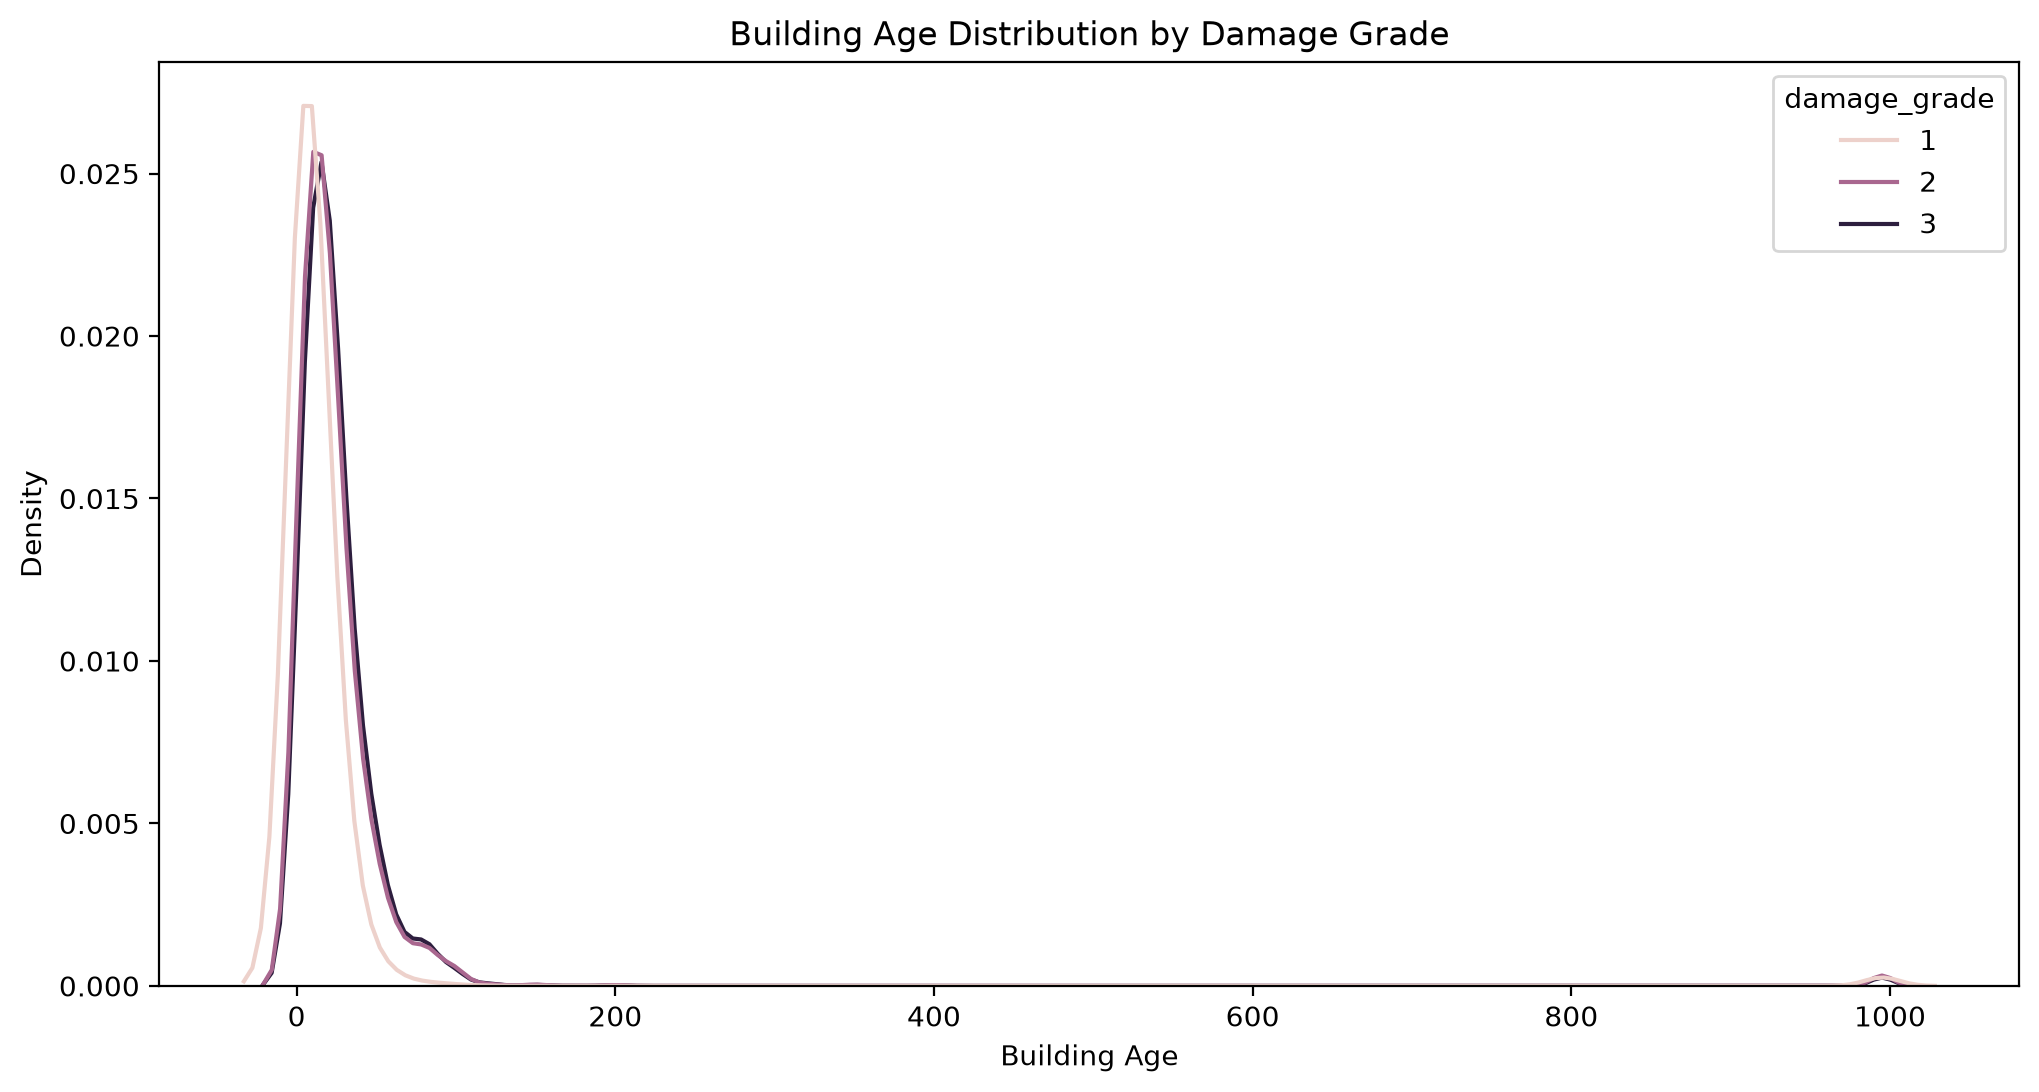

In [6]:
# 오래된 건물일수록 damage_grade가 높아질까?

plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=df,
    x='age',
    hue='damage_grade',
    fill=False,
    common_norm=False
)

plt.title('Building Age Distribution by Damage Grade')
plt.xlabel('Building Age')
plt.ylabel('Density')

plt.show()

In [7]:
df[['age', 'damage_grade']].corr(method='spearman')

# 상관성 = 0.173098 -> 약한 상관관계

,age,damage_grade
age,1.000000,0.173098
damage_grade,0.173098,1.000000


### 5. 건축에 사용된 자재 수 비교

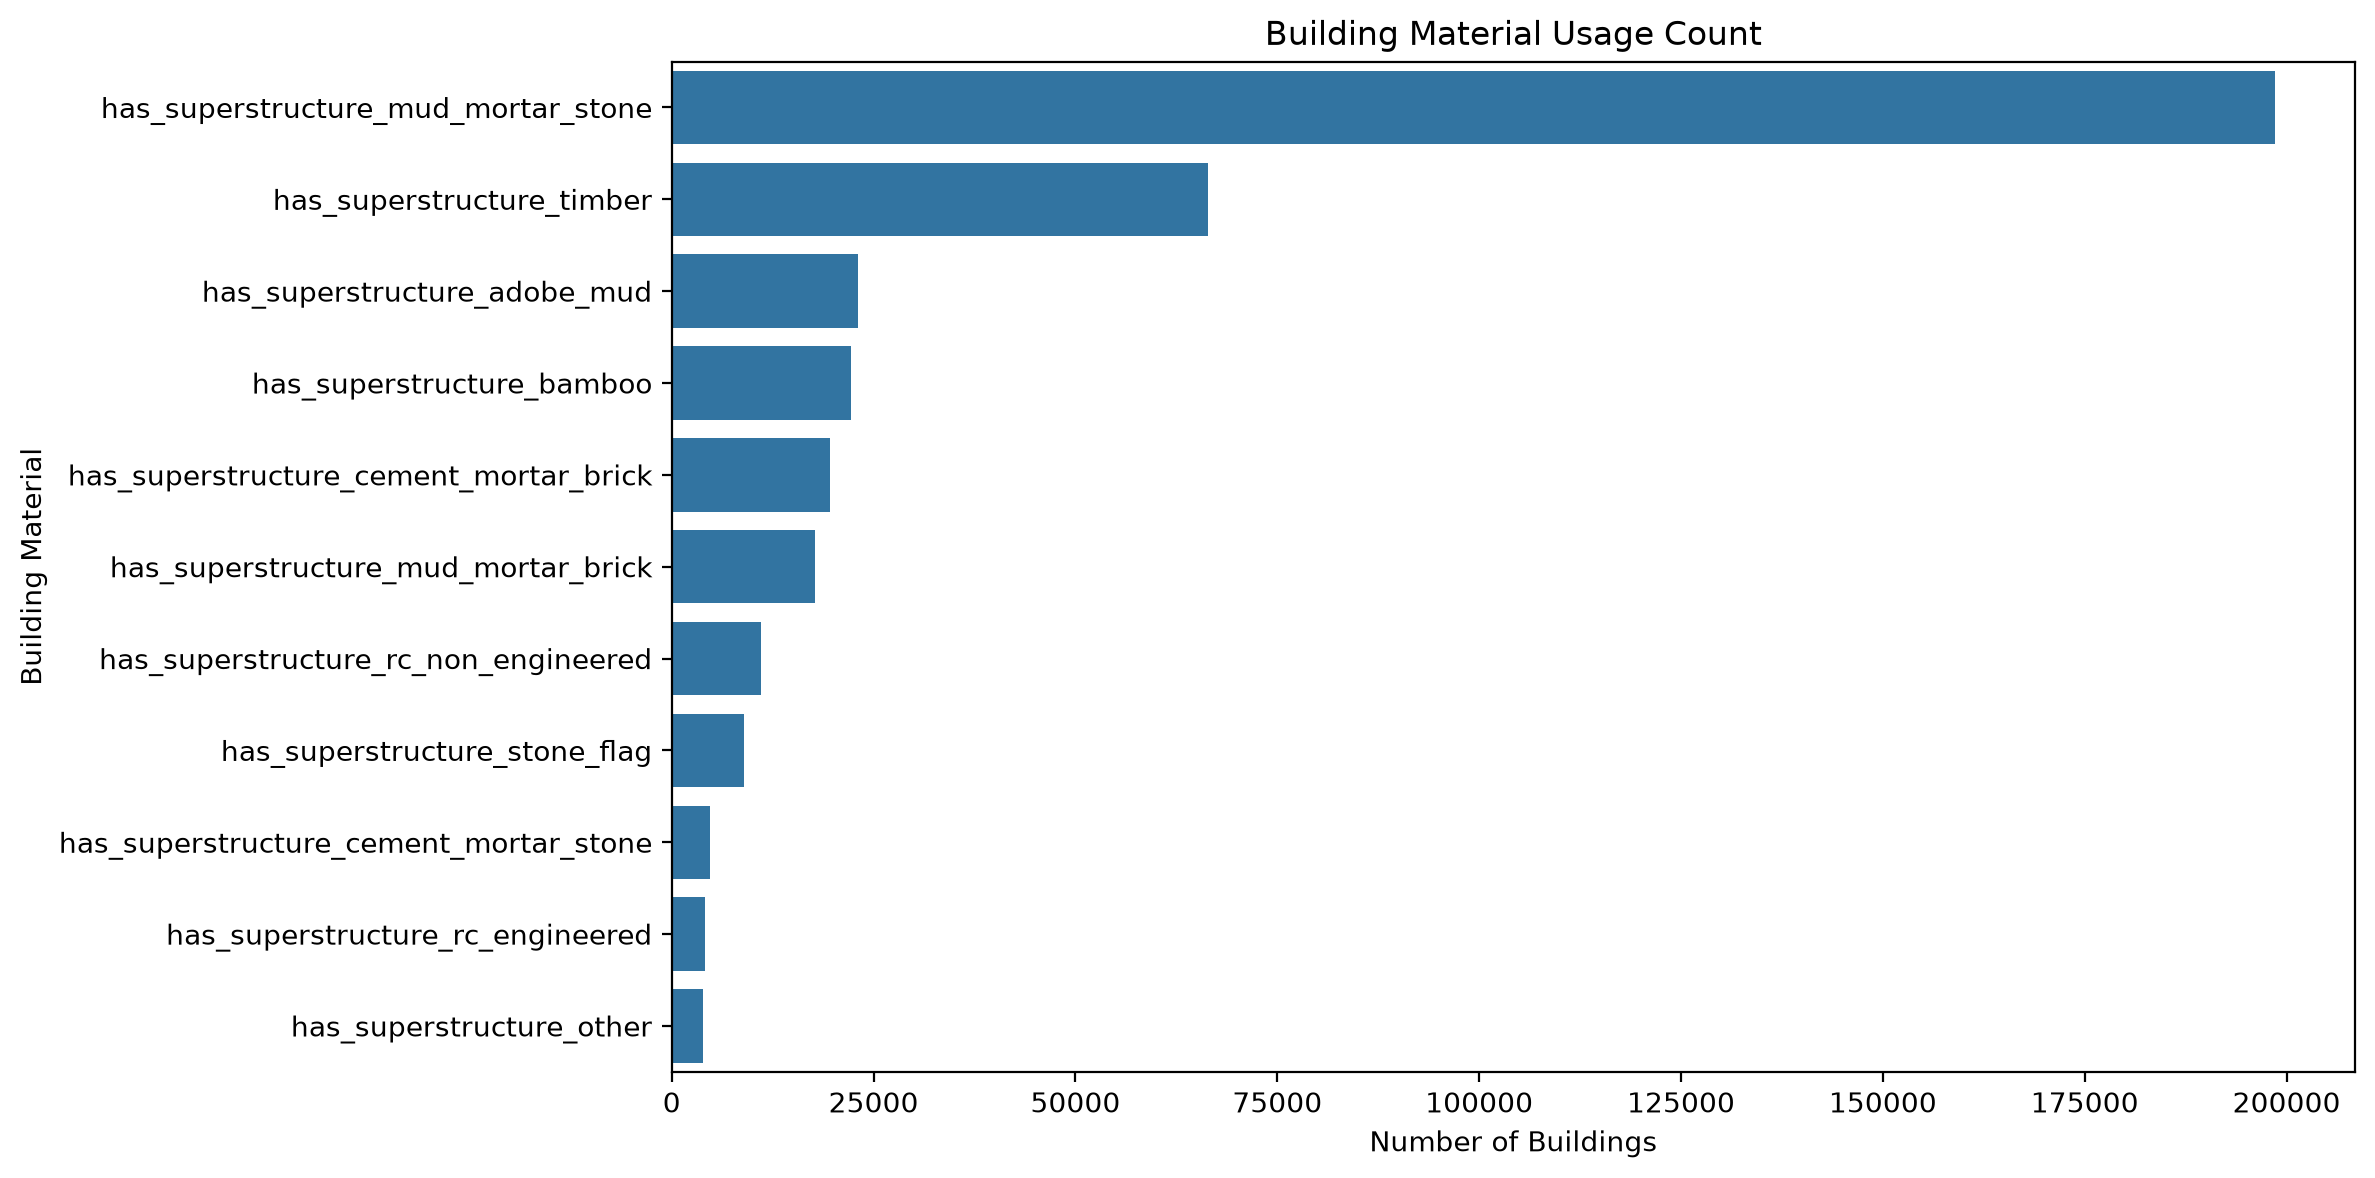

In [ ]:
# 건축 자재 컬럼 선택
material_cols = [col for col in df.columns
                 if col.startswith('has_superstructure_')]

# 자재별 1의 개수 계산
material_counts = df[material_cols].eq(1).sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

ax = sns.barplot(x=material_counts.values, y=material_counts.index)

plt.title('Building Material Usage Count')
plt.xlabel('Number of Buildings')
plt.ylabel('Building Material')

plt.tight_layout()          

plt.show()

### 6. 건축 자재별 지진 피해 3등급 파악

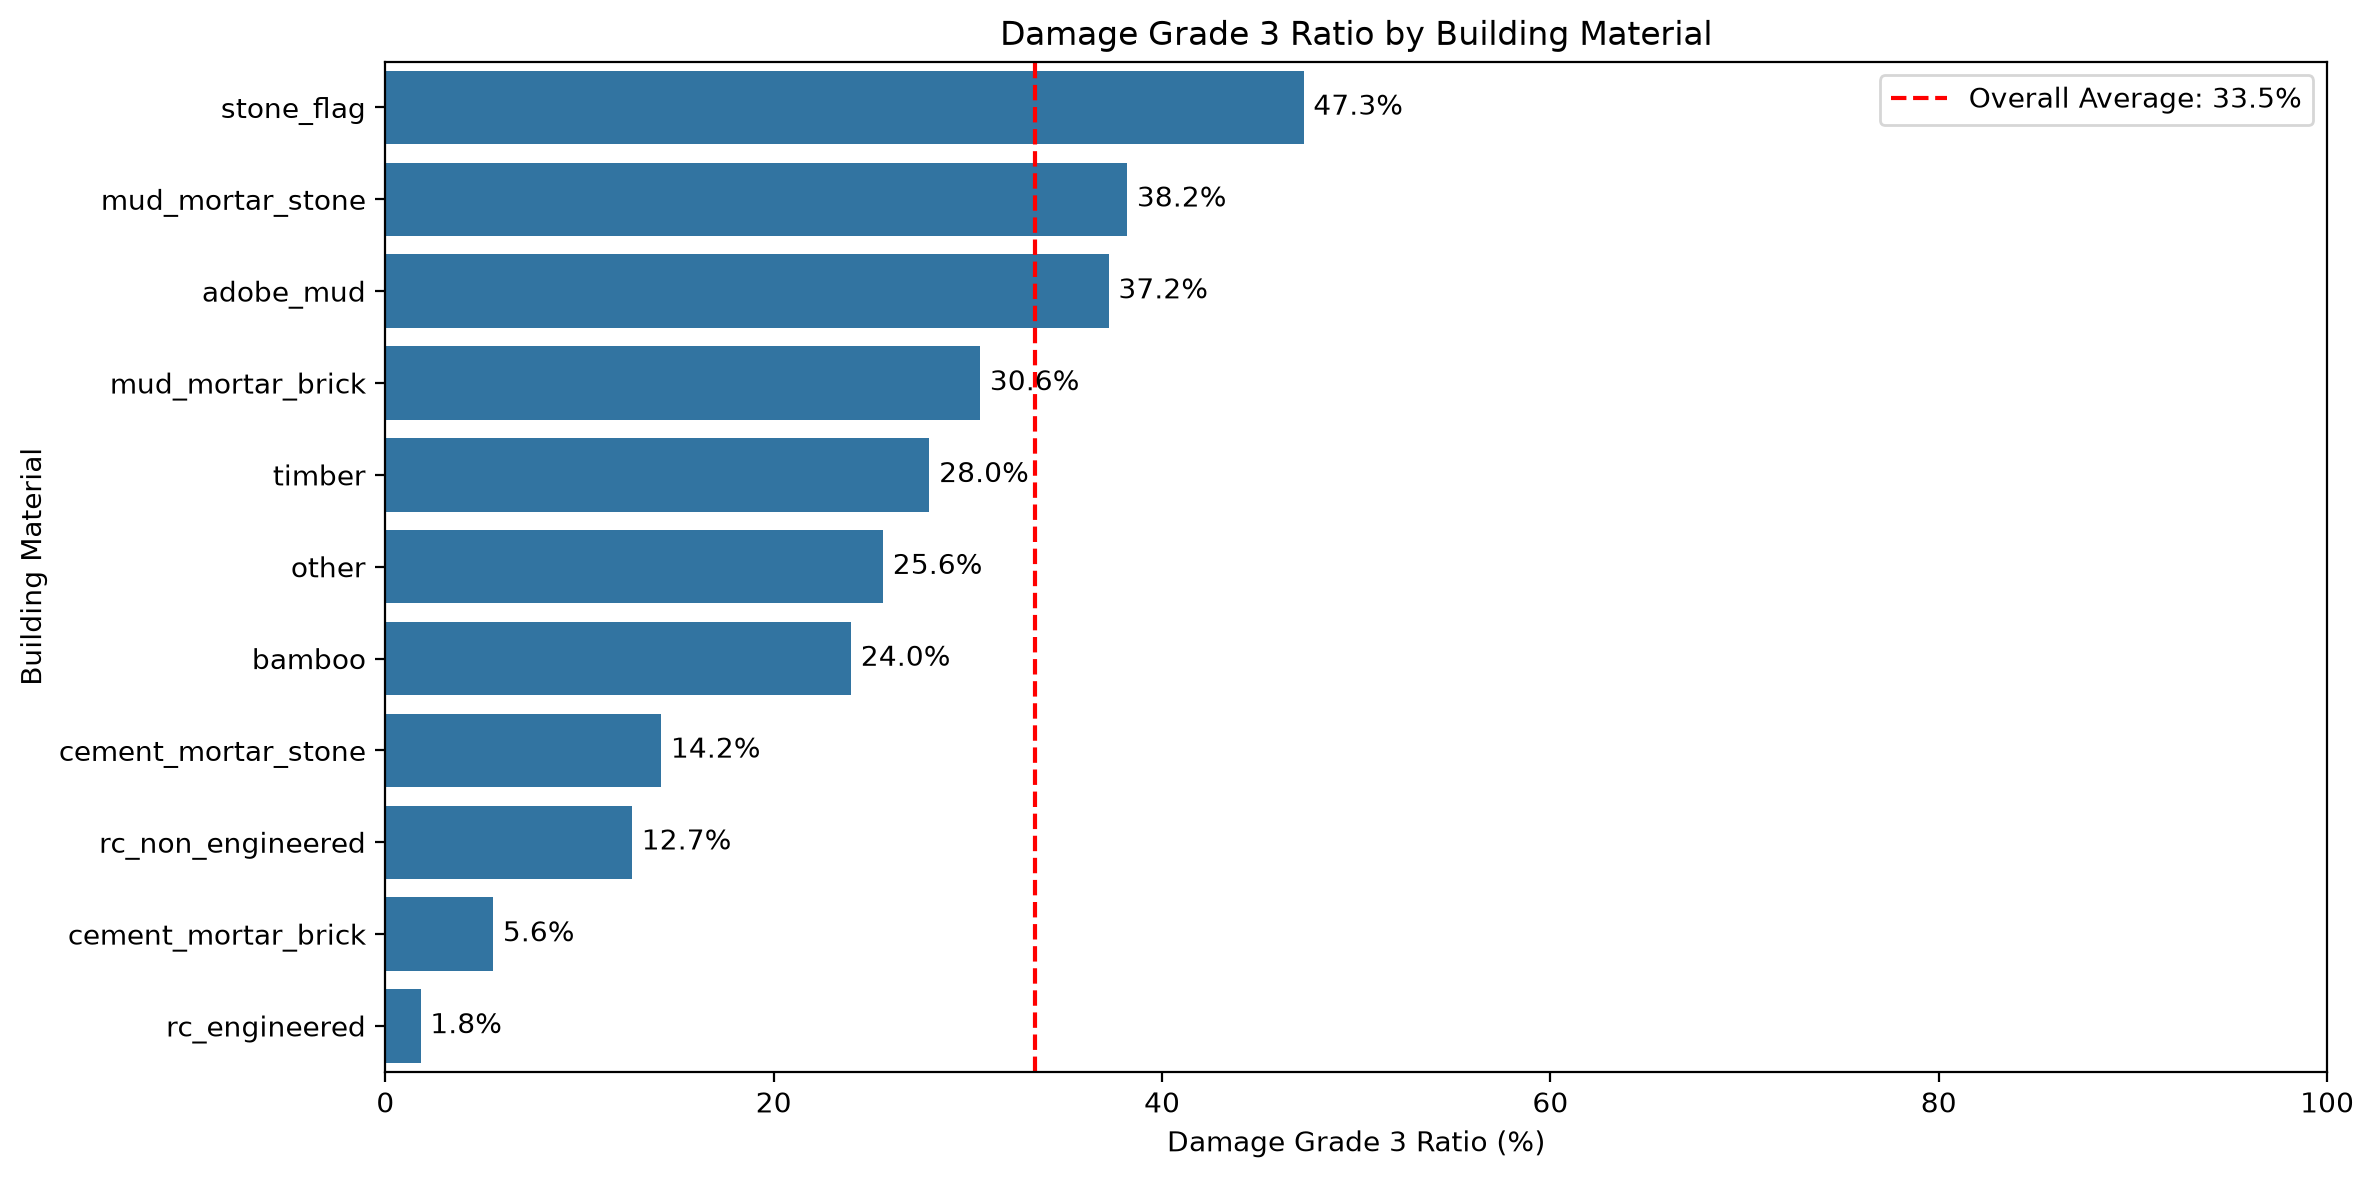

In [9]:
# 건축 자재 컬럼 선택
material_cols = [col for col in df.columns
                 if col.startswith('has_superstructure_')]

# 자재별 피해 3등급 비율 계산
result = []

for col in material_cols:
    # 해당 자재를 사용한 건물만 추출
    used = df[df[col] == 1]

    # 피해 등급이 3인 건물의 비율
    ratio = (used['damage_grade'] == 3).mean() * 100

    result.append([col.replace('has_superstructure_', ''), ratio])

# 데이터프레임 생성
material_damage = pd.DataFrame(result, columns=['Material', 'Damage Grade 3 Ratio'])

# 비율 높은 순으로 정렬
material_damage = material_damage.sort_values('Damage Grade 3 Ratio', ascending=False)

# 시각화
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=material_damage,
    x='Damage Grade 3 Ratio',
    y='Material'
)

# 막대 끝에 비율 표시
for i, v in enumerate(material_damage['Damage Grade 3 Ratio']):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')

plt.xlim(0, max(100, material_damage['Damage Grade 3 Ratio'].max() * 1.15))
plt.title('Damage Grade 3 Ratio by Building Material')
plt.xlabel('Damage Grade 3 Ratio (%)')
plt.ylabel('Building Material')


# 전체 건물에서 damage_grade=3 비율
total_ratio = (df['damage_grade'] == 3).mean() * 100

# 전체 평균 표시
plt.axvline(
    total_ratio,
    color='red',
    linestyle='--',
    label=f'Overall Average: {total_ratio:.1f}%'
)

plt.legend()

plt.tight_layout()
plt.show()

In [10]:
# 자재별 사용 건물 수

material_counts = df[material_cols].eq(1).sum()

display(material_counts.sort_values(ascending=False))

has_superstructure_mud_mortar_stone       198561
has_superstructure_timber                  66450
has_superstructure_adobe_mud               23101
has_superstructure_bamboo                  22154
has_superstructure_cement_mortar_brick     19615
has_superstructure_mud_mortar_brick        17761
has_superstructure_rc_non_engineered       11099
has_superstructure_stone_flag               8947
has_superstructure_cement_mortar_stone      4752
has_superstructure_rc_engineered            4133
has_superstructure_other                    3905
dtype: int64

> **해석**   
> `stone_flag`를 사용한 건물의 3등급 피해 비율은 47.3%로, 전체 평균인 33.5%보다 13.8%p 높다.   
> `mud_mortar_stone`, `adobe_mud` 또한 전체 평균보다 높은 피해 비율을 보인다.

---

> **유의점**  
> 한 건물에 여러 건축자재가 사용될 수 있다. 
> 

### 7. 부가적인 건물 사용 여부

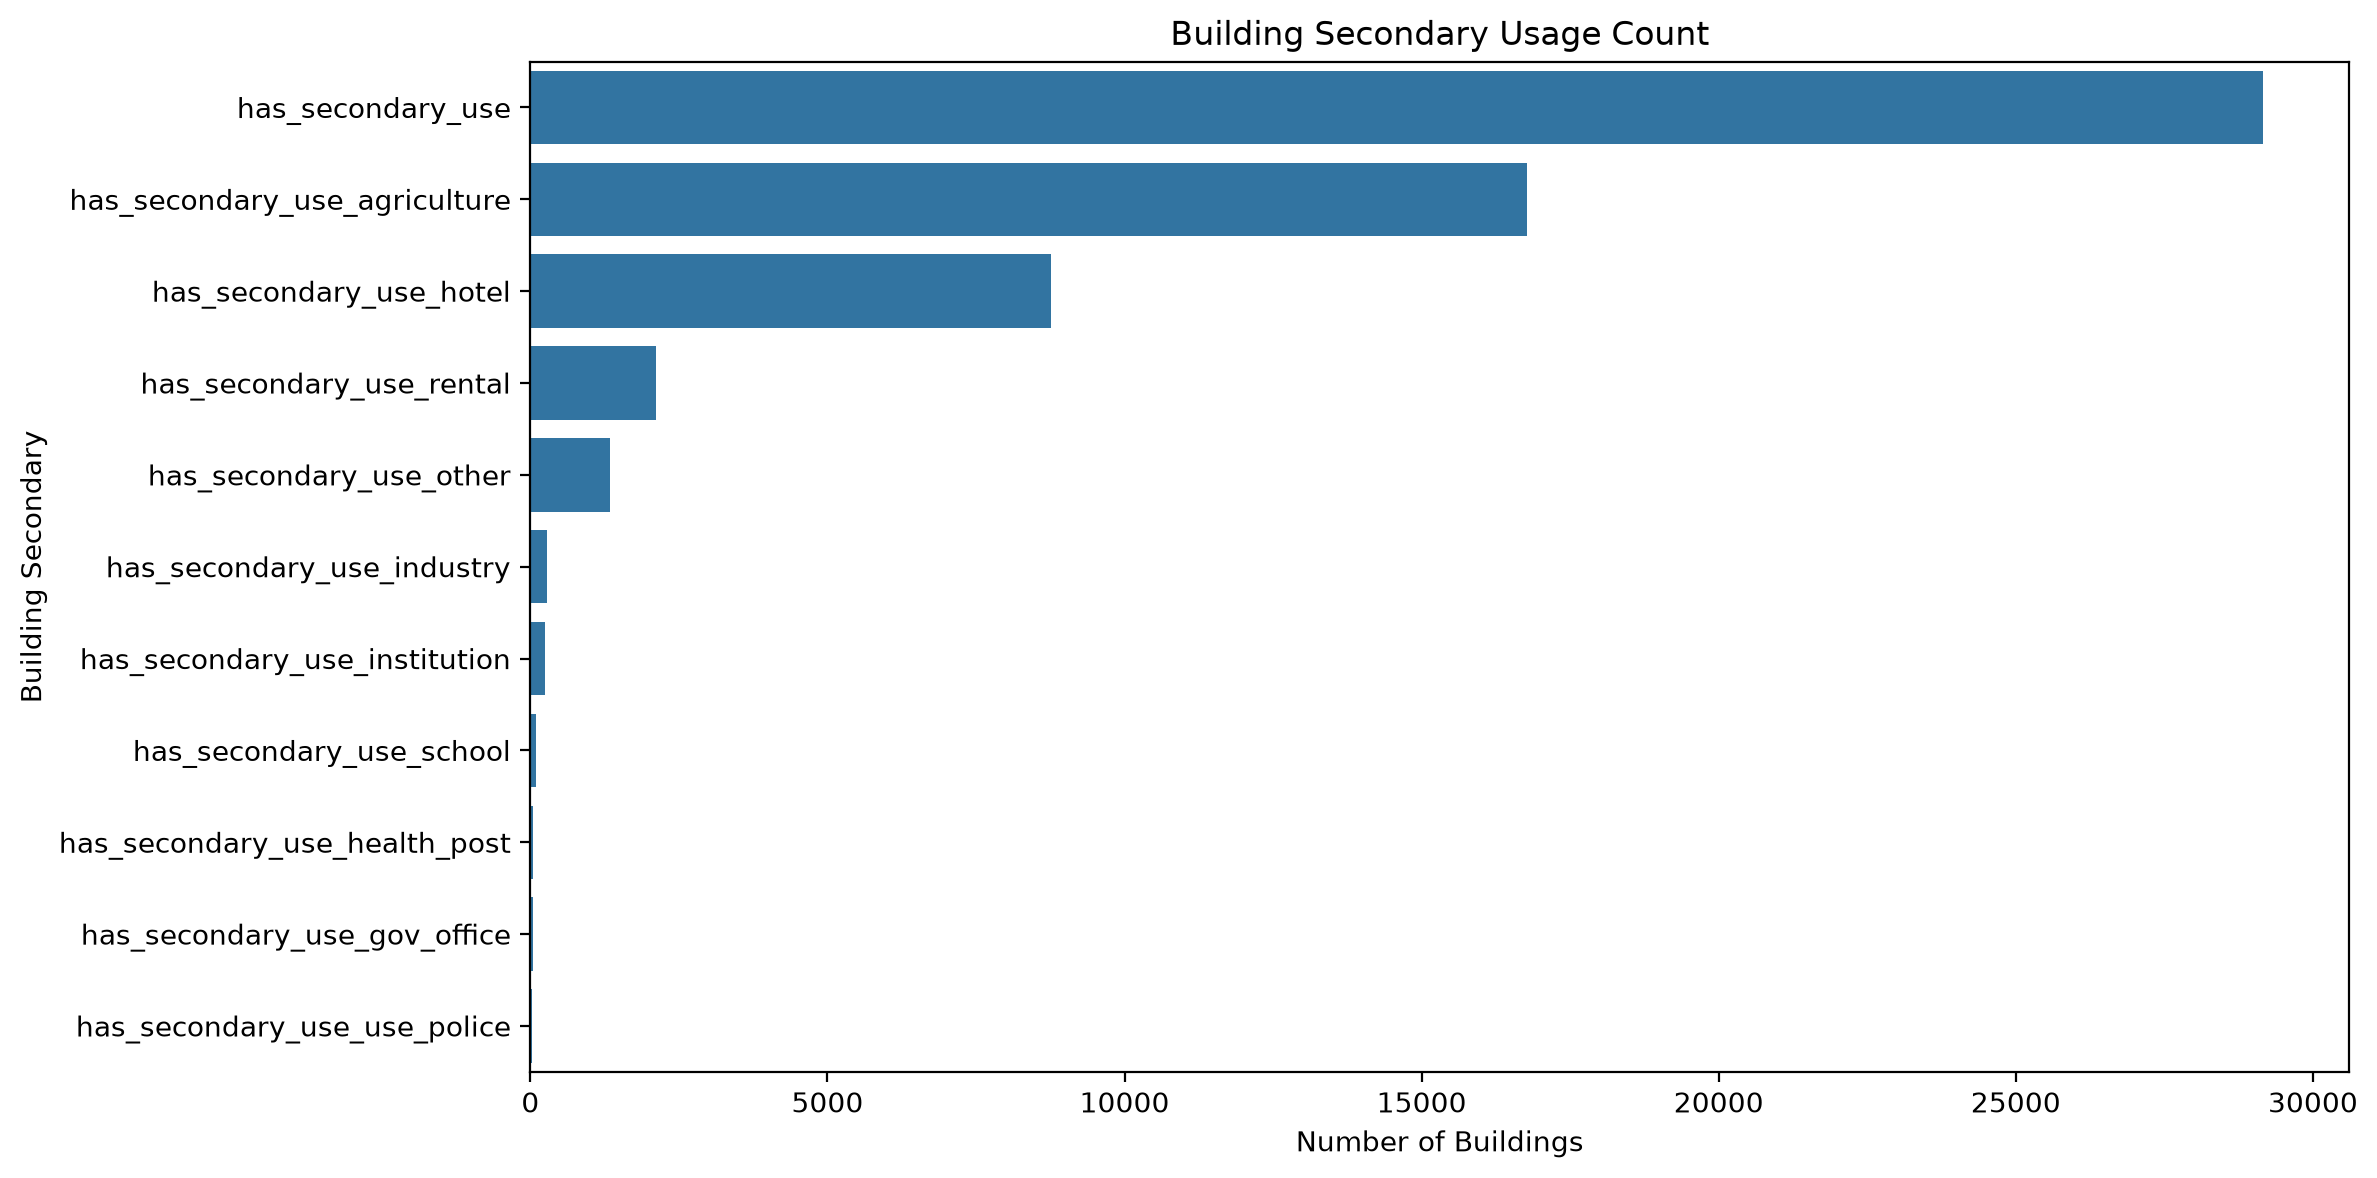

In [11]:
# 건축 용도 컬럼 선택
material_cols = [col for col in df.columns
                 if col.startswith('has_secondary_')]

# 용도 1의 개수 계산
material_counts = df[material_cols].eq(1).sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=material_counts.values,
    y=material_counts.index
)

plt.title('Building Secondary Usage Count')
plt.xlabel('Number of Buildings')
plt.ylabel('Building Secondary')

plt.tight_layout()
plt.show()

### 8. 부가적인 건물 사용여부별 3등급 피해 등급

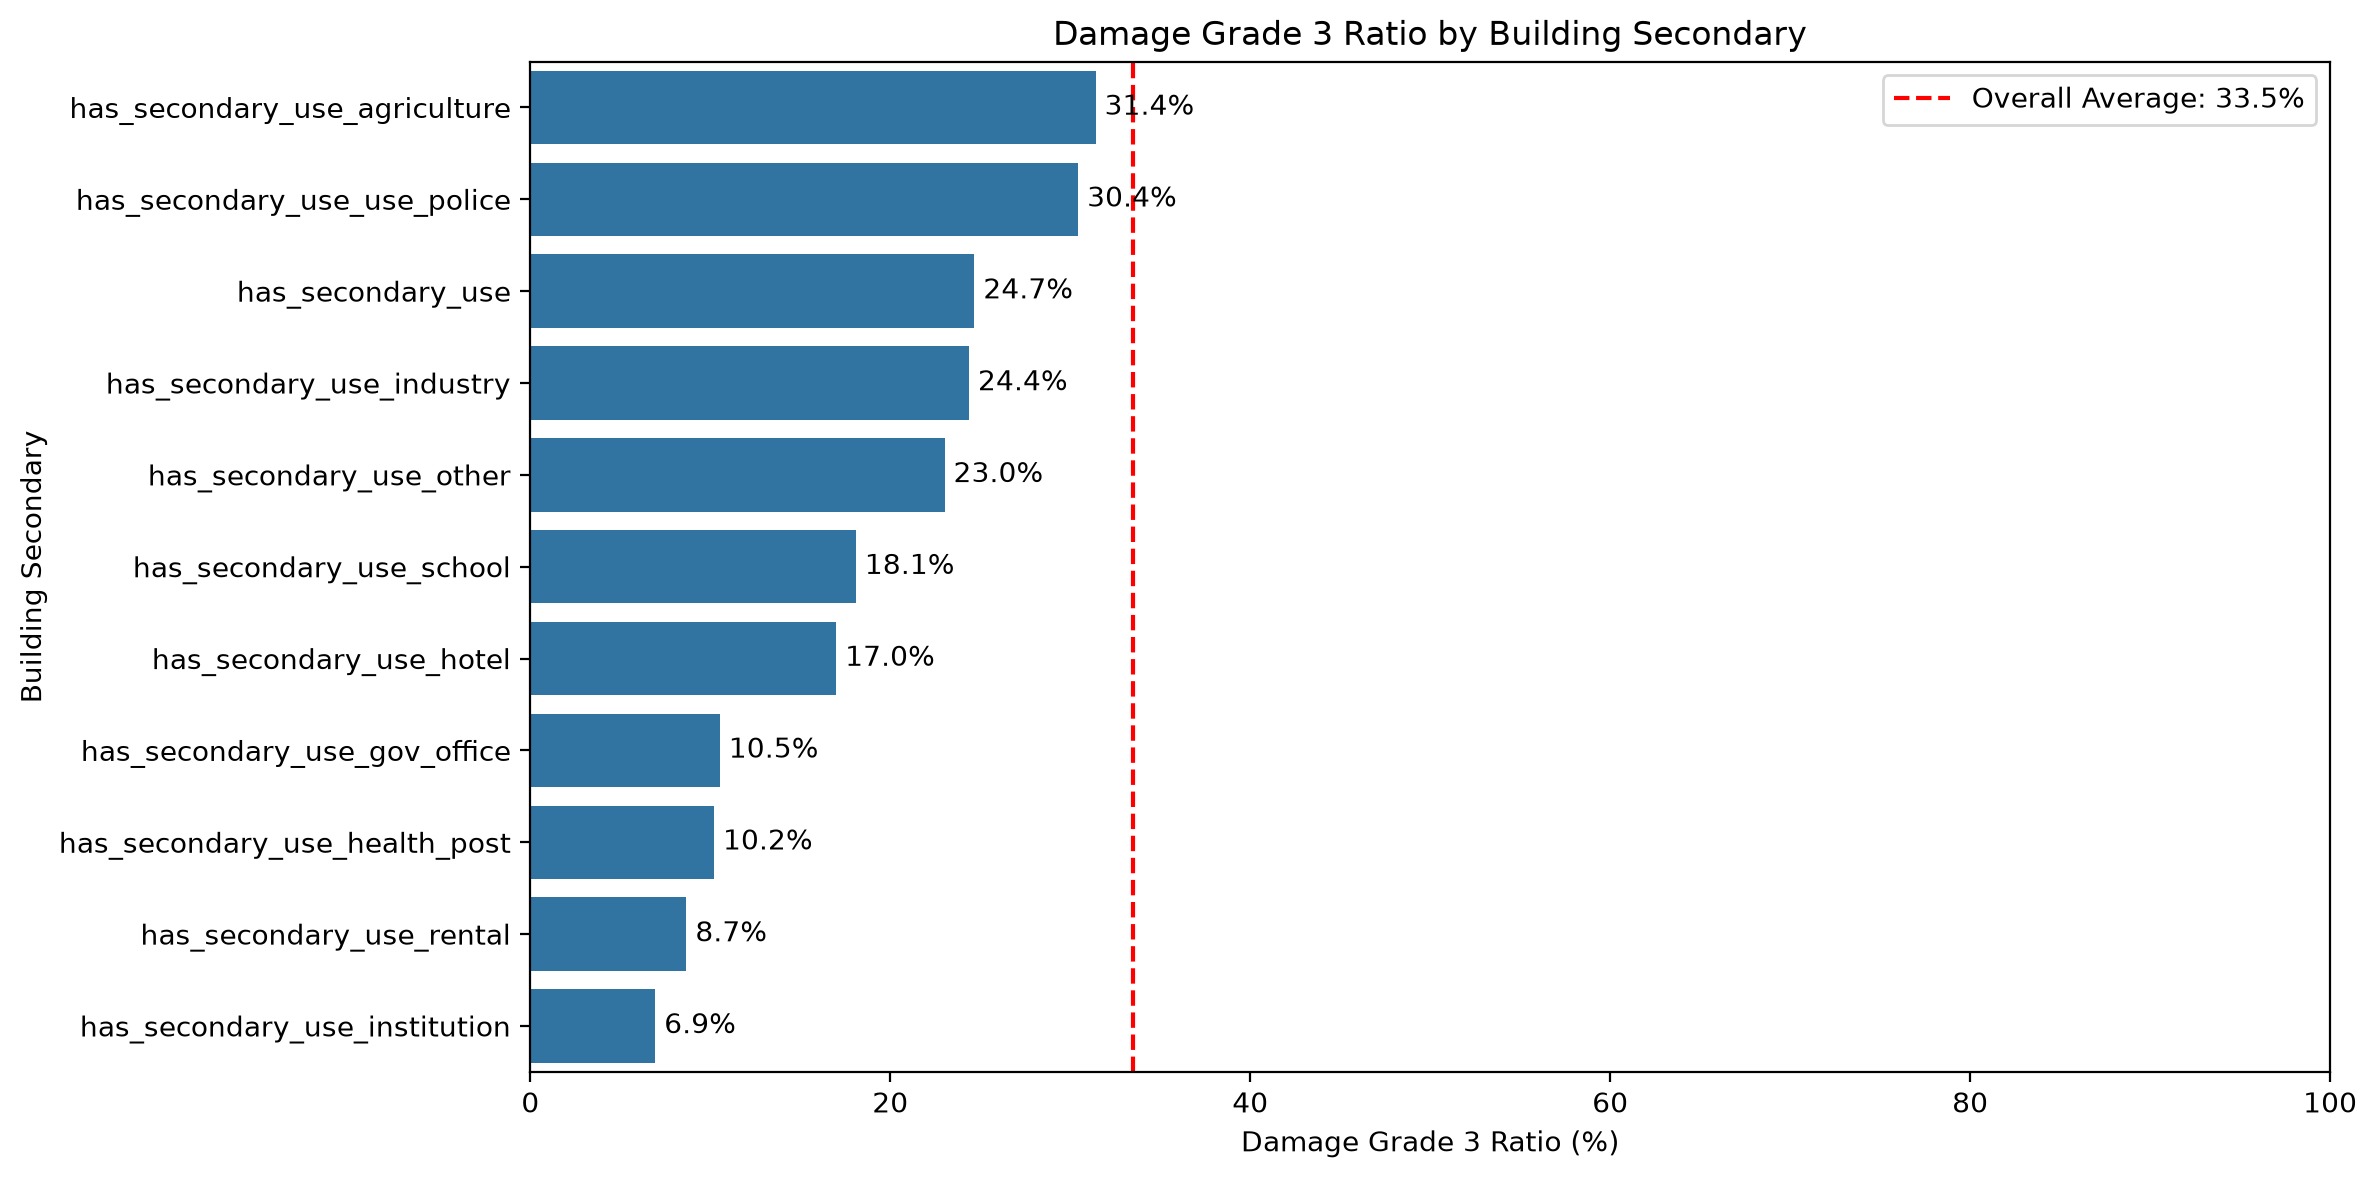

In [12]:
# 건축 자재 컬럼 선택
secondary_cols = [col for col in df.columns
                 if col.startswith('has_secondary_')]

# 자재별 피해 3등급 비율 계산
result = []

for col in secondary_cols:
    # 해당 자재를 사용한 건물만 추출
    used = df[df[col] == 1]

    # 피해 등급이 3인 건물의 비율
    ratio = (used['damage_grade'] == 3).mean() * 100

    result.append([col.replace('has_superstructure_', ''), ratio])

# 데이터프레임 생성
material_damage = pd.DataFrame(result, columns=['Material', 'Damage Grade 3 Ratio'])

# 비율 높은 순으로 정렬
material_damage = material_damage.sort_values('Damage Grade 3 Ratio', ascending=False)

# 시각화
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=material_damage,
    x='Damage Grade 3 Ratio',
    y='Material'
)

# 막대 끝에 비율 표시
for i, v in enumerate(material_damage['Damage Grade 3 Ratio']):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')

plt.xlim(0, max(100, material_damage['Damage Grade 3 Ratio'].max() * 1.15))
plt.title('Damage Grade 3 Ratio by Building Secondary')
plt.xlabel('Damage Grade 3 Ratio (%)')
plt.ylabel('Building Secondary')


# 전체 건물에서 damage_grade=3 비율
total_ratio = (df['damage_grade'] == 3).mean() * 100

# 전체 평균 표시
plt.axvline(
    total_ratio,
    color='red',
    linestyle='--',
    label=f'Overall Average: {total_ratio:.1f}%'
)

plt.legend()

plt.tight_layout()

plt.show()

### 9. 수치형 변수 상관관계

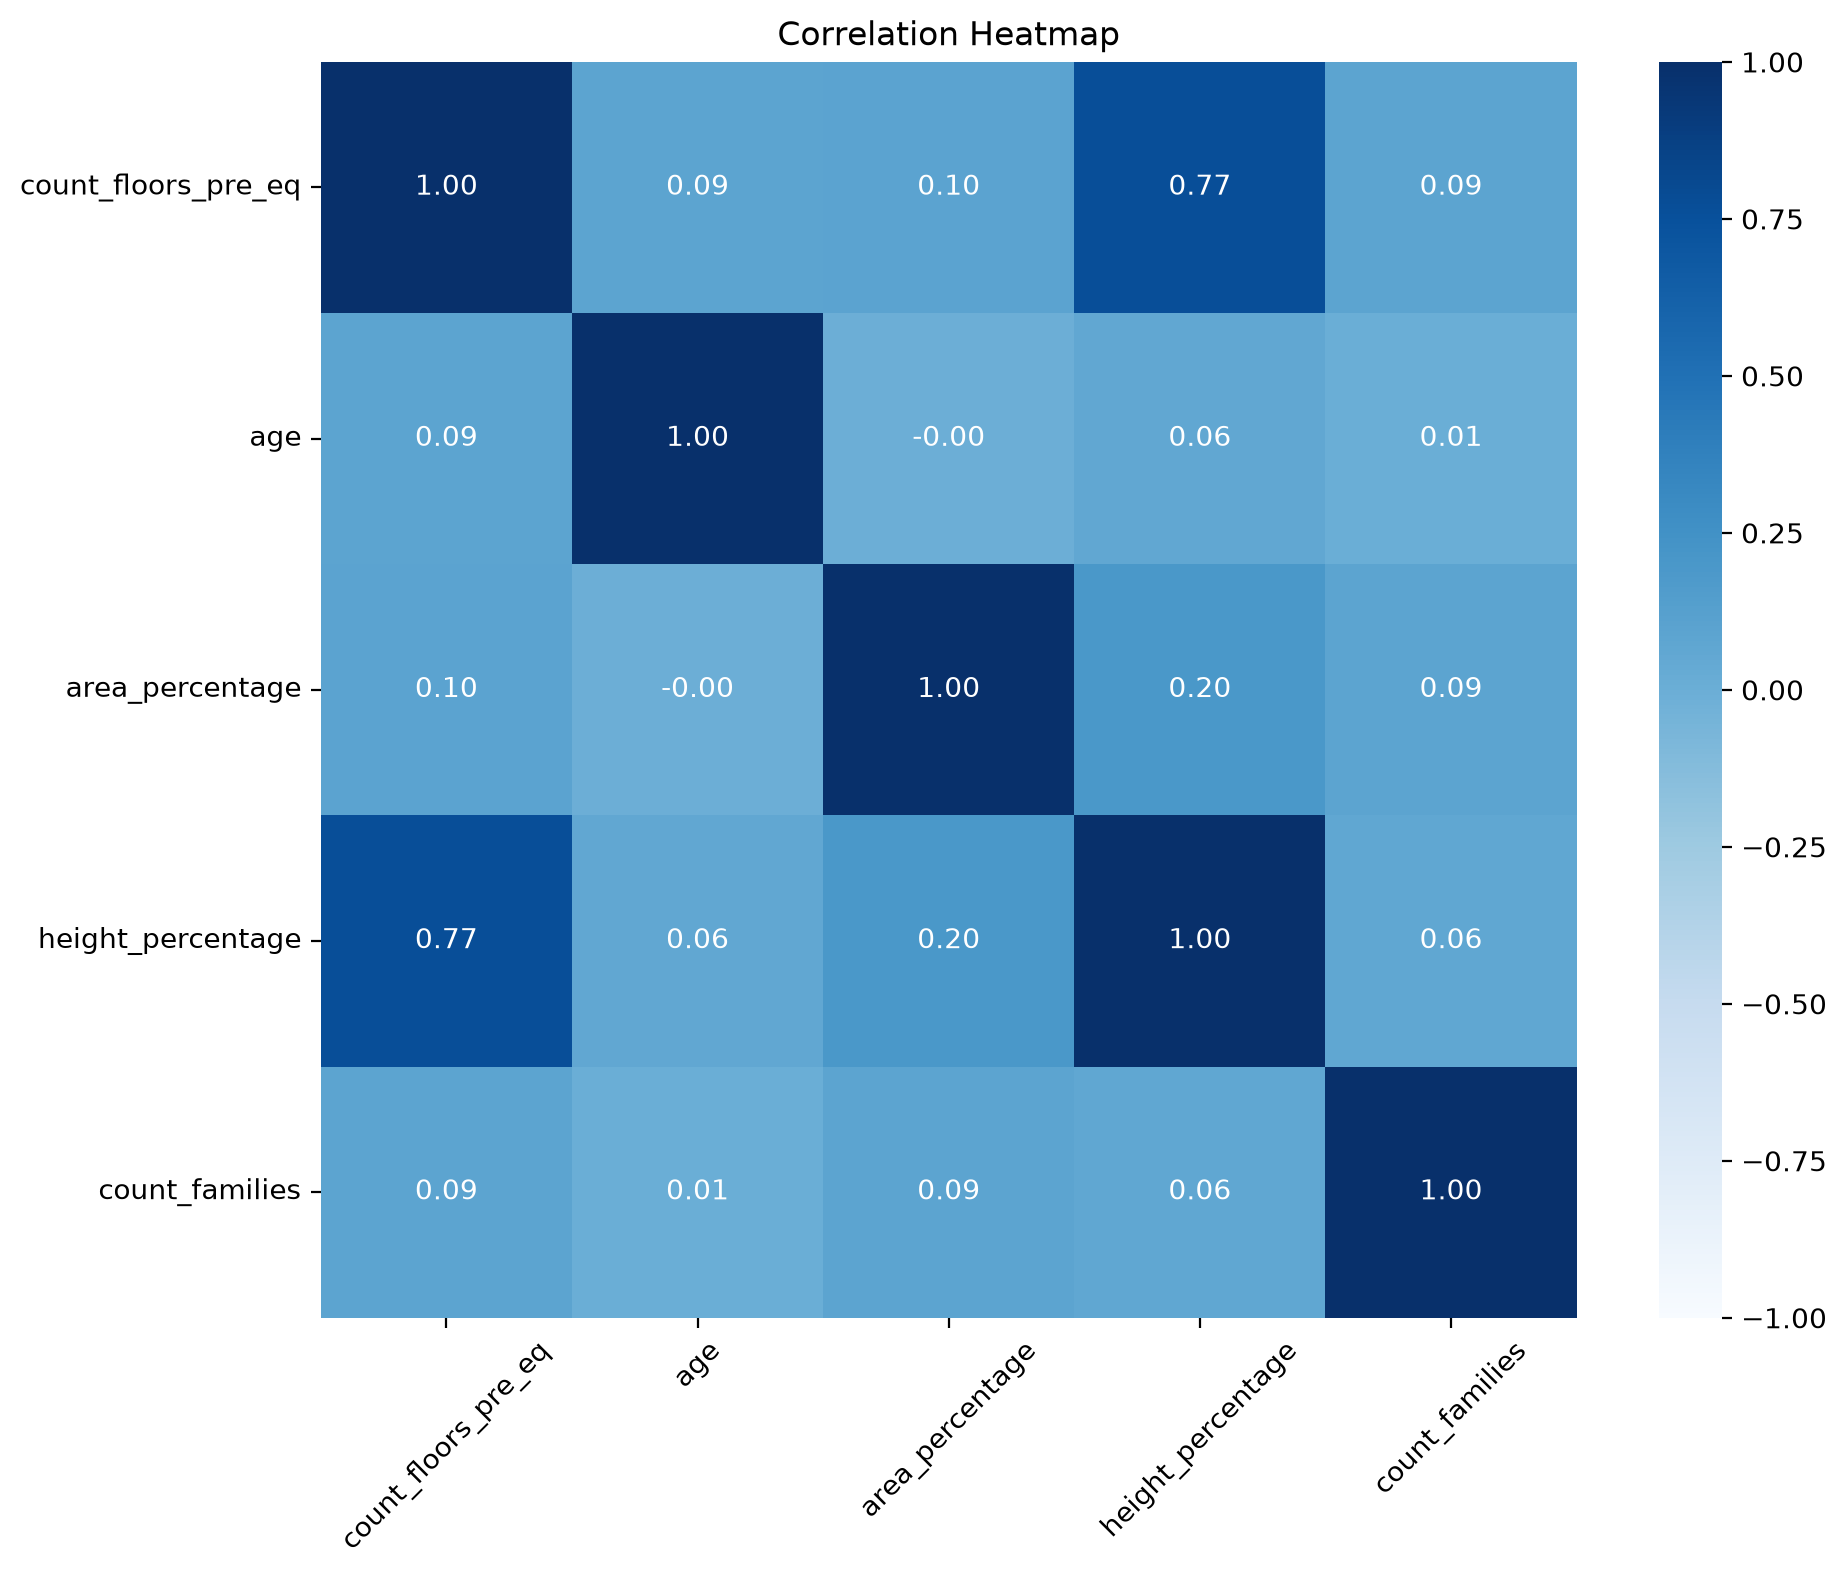

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 상관계수 계산
corr = df[num_cols].corr()

# 히트맵 시각화
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,          # 상관계수 숫자 표시
    fmt='.2f',           # 소수점 둘째 자리까지
    cmap='Blues',     # 색상 설정
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title('Correlation Heatmap')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Preprocessing

### 이상치 분포 확인 (연속형 데이터만 파악)

In [ ]:
df_outlier = df.copy()

# 이상치 처리에 사용할 컬럼
outliers_cols = [
    'count_floors_pre_eq',
    'age',
    'area_percentage',
    'height_percentage',
    'count_families'
]

for col in outliers_cols:
    Q1 = df_outlier[col].quantile(0.25)
    Q3 = df_outlier[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # 이상치 확인
    outlier = ((df_outlier[col] < lower) |
                     (df_outlier[col] > upper))


    print(f'{[col]}')
    print(f'이상치 개수 : {outlier.sum()}')
    print(f'이상치 비율 : {outlier.mean()/df_outlier * 100:.2f}%')
    print('-' * 40)

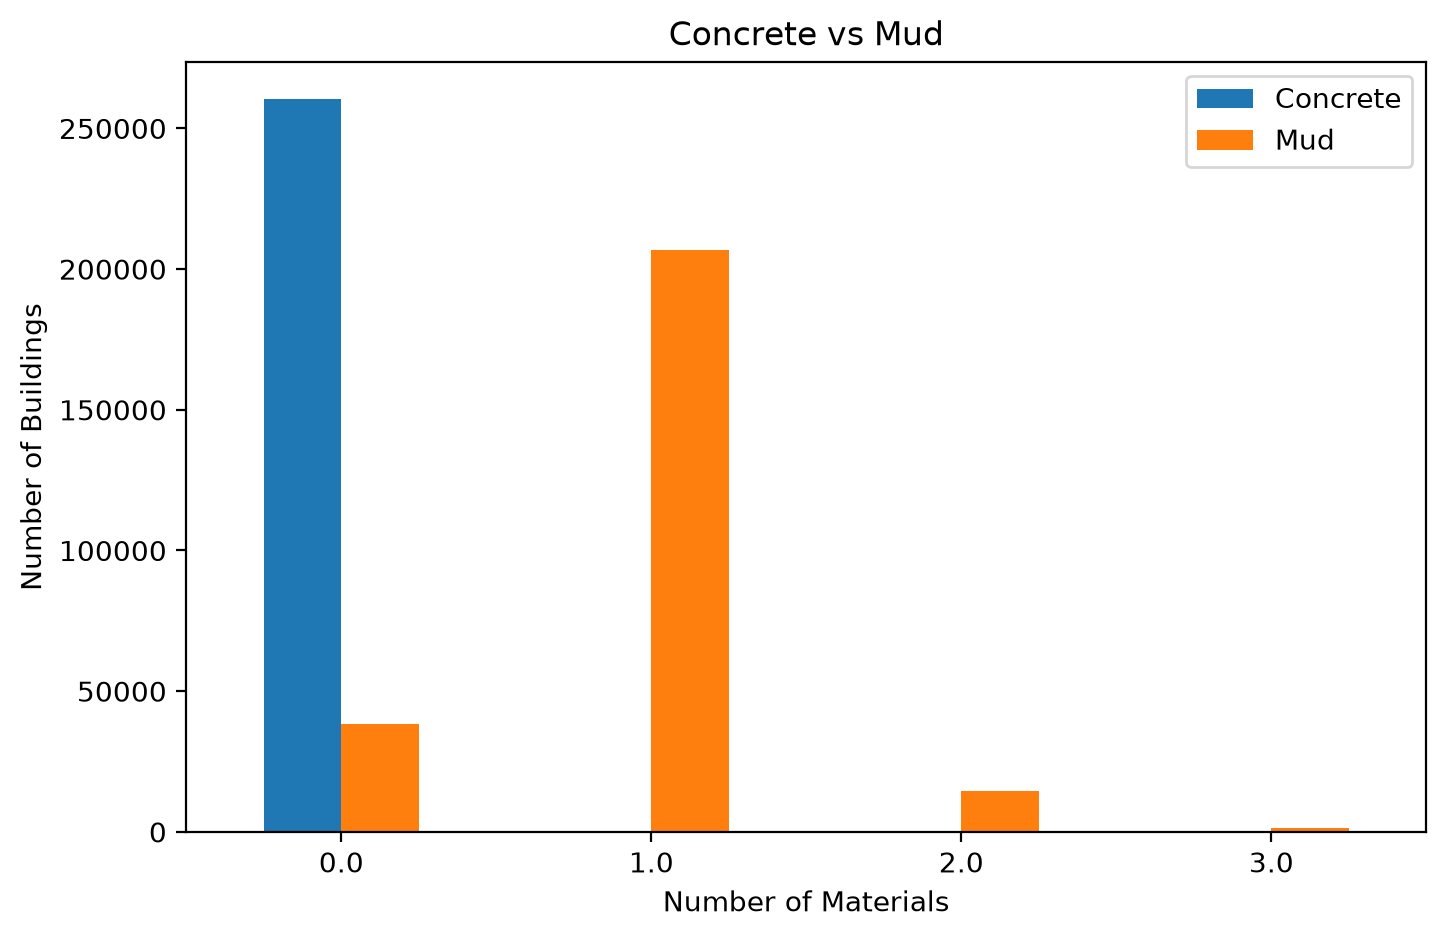

In [ ]:
material_cols = [
    col for col in df.columns
    if col.startswith('has_superstructure_')
] # 건물에 사용한 재료 컬럼

# 7) 건축재료를 그룹별로 나누는 파생변수
    # 7-1) concrete_count 
df['concrete_count'] = df[[col for col in material_cols if 'concrete' in col]].sum(axis=1)

    # 7-2) mud_count
df['mud_count'] = df[[col for col in material_cols if 'mud' in col]].sum(axis=1)


count_df = pd.DataFrame({
    'Concrete': df['concrete_count'].value_counts(),
    'Mud': df['mud_count'].value_counts()
}).fillna(0).sort_index()

count_df.plot(kind='bar', figsize=(8, 5))


plt.title('Concrete vs Mud')
plt.xlabel('Number of Materials')
plt.ylabel('Number of Buildings')

plt.xticks(rotation=0)
plt.legend()

plt.show()